# TL;DR:

Exercise datasets:
```python
diabetes_df = pd.read_csv('tables/diabetes_clean.csv')
X = diabetes_df.copy().drop('diabetes', axis = 1)
y = diabetes_df.copy()['diabetes']

music_df = pd.read_csv('tables/music_clean.csv')
```
---



Train test split
```python
from sklearn.model_selection import train_test_split
X = df.drop(y_col, axis = 1)
y = df[y_col]
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42, stratify = y #requires binary class, as knn
)
```
---



KNN 
```python
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 5)
predict = knn.predict(X, y)
knn_accuracy = knn.score(X, y)
```
---


Linear Regression
```python
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
predict = reg.predict(X)
rsquared = reg.score(X,y) # KNN: accuracy; regression: rsquared
```
---

Rsquared, RMSE
```python
from sklearn.metrics import mean_squared_error
# Compute R-squared
r_squared = reg.score(X_test, y_test)
# Compute RMSE
rmse = mean_squared_error(y_test, y_pred, squared=False)
```
---

Logistic Regression:
```python
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
```
---

roc curve; roc_auc_score
```python
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, tresholds = roc_curve(y_test, y_pred_probs)
score = roc_auc_score(y_test, y_pred_probs)
plt.plot([0,1], [0,1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
```
---

Confusion matrix; classification report
```python
from sklearn.metrics import confusion_matrix, classification_report
confusion_matrix(y_test, y_pred)
```
Results order:  

TN FP   
FN TP  


columns = predictions (N = predicted negative)  
rows = actuals (T = predicted equals truth)  
ex: FN:
 - N = predicted Negative  
 - F = prediction is false: data is actually positive  
 - FN: you predicted falsely that it is negative  
---

Decision tree (only briefly previewed)
```python
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier()
```
---

KFold, cross_val_score
```python
from sklearn.model_selection import KFold, cross_val_score
kf = KFold(n_splits = 6, shuffle = True, random_state = 5)
reg = LinearRegression()
cv_scores = cross_val_score(reg, X, y, cv = kf, scoring = 'neg_mean_squared_error')
print(cv_scores) # for regressions: Rsquared; for classification: Accuracy
# Calcualte RMSE
rmse = np.sqrt(-cv_scores)
```
---

GridSearchCV
```python
from sklearn.model_selection import GridSearchCV
kf = KFold(n_splits = 5, shuffle = True, random_state = 42)
param_grid = {
    'alpha': np.arange(1e-4, 1, 10),
    'solver': ['sag','lsqr'],
}
ridge = Ridge()

ridge_cv = GridSearchCV(
    ridge, 
    param_grid, 
    cv = kf, 
    )
```
---

Pipeline, imputation, standardscaler
```python
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

steps = Pipeline(
    [
        ('impute', SimpleImputer()),
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha = 0.5)),        
    ]
)

scaler = StandardScaler()
X_train = scaler.fit_transform()
X_test = scaler.transform()
```
---

# Chapter 1

Supervised learning:
- classification  
  - binary classification  
- regression  
  - "analogic"
  
Feature = predictor variable = independent variable (x axis)  
Target variable = dependent variable = response variable (y axis)

Requirements:  
- no missing values
- data in numeric values 
- data in pandas dataframe / numpy array  

Scikit-learn syntax:

```python
from sklearn.module import Model
model = Model()
model.fit(X, y)
predictions = model.predict(X_new)
print(predictions)
```

In [1]:
(55/19)**(1/2)

1.7013926184468013

   height  weight   bmi score colors
0    1.67      51 18.29     u   blue
1    1.82      62 18.72     u   blue
2    1.76      69 22.28     n  green
3    1.73      64 21.38     n  green
4    1.72      65 21.97     n  green
5    1.74      56 18.50     u   blue
6    1.69      58 20.31     n  green
7    1.73      57 19.05     n  green
8    1.70      55 19.03     n  green


,height,weight
0,1.70,57


,height,weight,bmi,score,colors,height2,weight2,eucl
0,1.67,51,18.29,u,blue,0.00,36,6.00
1,1.82,62,18.72,u,blue,0.01,25,5.00
2,1.76,69,22.28,n,green,0.00,144,12.00
3,1.73,64,21.38,n,green,0.00,49,7.00
4,1.72,65,21.97,n,green,0.00,64,8.00
5,1.74,56,18.50,u,blue,0.00,1,1.00
6,1.69,58,20.31,n,green,0.00,1,1.00
7,1.73,57,19.05,n,green,0.00,0,0.03
8,1.70,55,19.03,n,green,0.00,4,2.00


result: ['u']


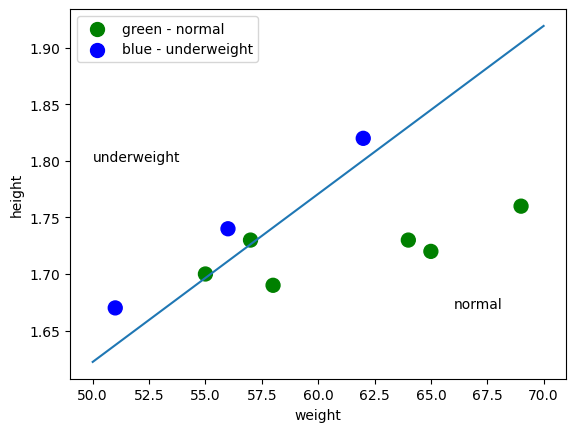

In [2]:
# KNN - K nearest neigbors
# https://www.youtube.com/watch?v=4HKqjENq9OU

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
pd.options.display.float_format = lambda x: f'{x:,.2f}'
df = pd.DataFrame(
    data = {
        'height':[1.67, 1.82,1.76 ,1.73, 1.72, 1.74 ,1.69, 1.73, 1.70],
        'weight':[51 , 62 , 69 ,64 , 65 , 56  ,58  ,57 , 55],
    }
).assign(
    bmi = lambda x: x['weight']/(x['height']**2),
    score = lambda x: np.where(x['bmi'] <= 19, 'u', 'n'),
    colors = lambda x: x['score'].map({'n':'green','u':'blue'})
    )

print(df)

df_target = pd.DataFrame(
    data = {
        'height':[1.70],
        'weight':[57],
    }
)

display(df_target)



# plt.scatter(x = df_target['weight'], y = df_target['height'], c = 'red', s = 100, label = 'red: target' )
plt.scatter(x = df['weight'], y = df['height'], c = df['colors'], s = 100  )
plt.scatter(x = [], y = [], c = 'green', label = 'green - normal', s = 100)
plt.scatter(x = [], y = [], c = 'blue', label = 'blue - underweight', s = 100)
plt.plot([50,70], [(50/19)**(1/2), (70/19)**(1/2)])
plt.legend()
plt.xlabel('weight')
plt.ylabel('height')
plt.text(x = 66, y = 1.67, s = 'normal')
plt.text(x = 50, y = 1.80, s = 'underweight')
df_knn = (
    df
    .assign(height2 =  (df['height'] - df_target['height'].values)**2)
    .assign(weight2 =  (df['weight'] - df_target['weight'].values)**2)
    .assign(eucl =  lambda x: (x['height2'] + x['weight2'])**(1/2))    
)

display(df_knn)

# get knn of 3
print('result:', df_knn.head(6).sort_values('eucl')['score'].head(3).value_counts().head(1).index.values)
# -> it is normal!

## CAREFUL!!! KNN would be 'underweight' if you only considered the first 7 rows!

In [3]:
# with sklearn knn, it is always 'n'... go figure
# Import KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier


# Create arrays for the features and the target variable
y = df["score"].values
X = df[['weight','height']].values

dic = {}
for i in range(1,len(df)):
    # Create a KNN classifier with 6 neighbors
    knn = KNeighborsClassifier(n_neighbors = i)

    # Fit the classifier to the data
    knn.fit(X, y)

    print(f'for {i} neighbors, score is:', knn.predict(df_target.values))
    dic[i] = knn.fit(X,y)

dic


for 1 neighbors, score is: ['u']
for 2 neighbors, score is: ['n']
for 3 neighbors, score is: ['u']
for 4 neighbors, score is: ['n']
for 5 neighbors, score is: ['n']
for 6 neighbors, score is: ['n']
for 7 neighbors, score is: ['n']
for 8 neighbors, score is: ['n']


{1: KNeighborsClassifier(n_neighbors=1),
 2: KNeighborsClassifier(n_neighbors=2),
 3: KNeighborsClassifier(n_neighbors=3),
 4: KNeighborsClassifier(n_neighbors=4),
 5: KNeighborsClassifier(),
 6: KNeighborsClassifier(n_neighbors=6),
 7: KNeighborsClassifier(n_neighbors=7),
 8: KNeighborsClassifier(n_neighbors=8)}

,account_length,customer_service_calls,churn
0,128,1,0
1,107,1,0
2,137,0,0
3,84,2,0
4,75,3,0
...,...,...,...
3328,192,2,0
3329,68,3,0
3330,28,2,0
3331,184,2,0


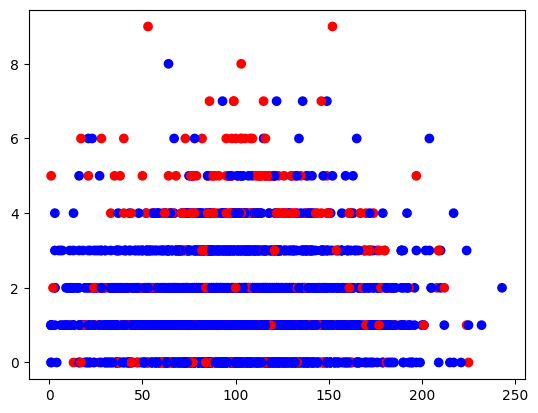

In [4]:
# datacamp exercise (finally!)

churn_df = pd.read_csv('tables/telecom_churn_clean.csv').drop('Unnamed: 0', axis = 1)

plt.scatter(x = churn_df['account_length'], y = churn_df['customer_service_calls'], c = churn_df['churn'].map({0:'blue',1:'red'}))

churn_df[['account_length','customer_service_calls','churn']]

In [5]:
X_new = np.array([[30.0, 17.5],
                  [107.0, 24.1],
                  [213.0, 10.9]])


Text(0, 0.5, 'customer service calls')

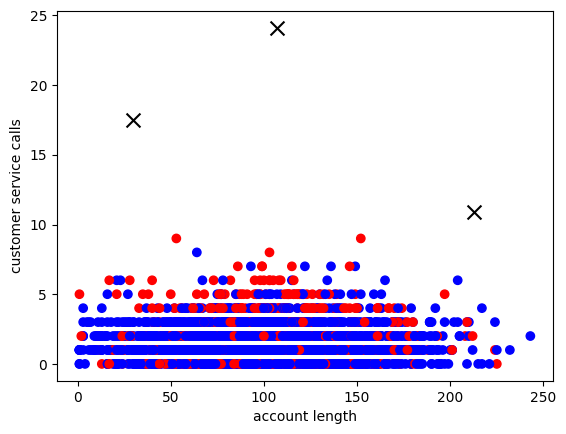

In [6]:
plt.scatter(x = churn_df['account_length'], y = churn_df['customer_service_calls'], c = churn_df['churn'].map({0:'blue',1:'red'}))
plt.scatter(x = [i[0] for i in X_new], y = [i[1] for i in X_new], marker = 'x', s = 100, c = 'k')
plt.xlabel('account length')
plt.ylabel('customer service calls')

In [7]:
churn_df[['account_length','customer_service_calls','churn']].agg(['mean','median'])

,account_length,customer_service_calls,churn
mean,101.06,1.56,0.14
median,101.00,1.00,0.00


In [8]:
X_new

array([[ 30. ,  17.5],
       [107. ,  24.1],
       [213. ,  10.9]])

In [9]:
# trying manual KNN with churn data
# -> it works!

df_c = churn_df[['account_length','customer_service_calls','churn']].copy()

for n,i in enumerate(X_new):
    df_c[f'target_{n}'] = str(i)
    df_c[f'eucl_{n}'] = (((df_c['account_length'] - i[0])**2) + ((df_c['customer_service_calls'] - i[1])**2))**(1/2)

display(df_c.head())
    
(
    df_c.sort_values('eucl_0').head(6)['churn'].mode()[0],
    df_c.sort_values('eucl_1').head(6)['churn'].mode()[0],
    df_c.sort_values('eucl_2').head(6)['churn'].mode()[0],

)
    

,account_length,customer_service_calls,churn,target_0,eucl_0,target_1,eucl_1,target_2,eucl_2
0,128,1,0,[30. 17.5],99.38,[107. 24.1],31.22,[213. 10.9],85.57
1,107,1,0,[30. 17.5],78.75,[107. 24.1],23.10,[213. 10.9],106.46
2,137,0,0,[30. 17.5],108.42,[107. 24.1],38.48,[213. 10.9],76.78
3,84,2,0,[30. 17.5],56.18,[107. 24.1],31.90,[213. 10.9],129.31
4,75,3,0,[30. 17.5],47.28,[107. 24.1],38.33,[213. 10.9],138.23


(0, 1, 0)

Measuring model performance

Accuracy:
correct predictions / total observations


Split data
- Training set -> Fit / train classifier on training set
- Test set         
- Training + test set: Calculate accuracy using test set

```python
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=21, stratify = y)

knn = KNeighborsClassifier(n_neighbors=6)
knn.fit(X_train, y_train)
print(knn.score(X_test, y_test))
```

Underfitting and Overfitting:
- Thinking about the underweight/normal weight example:
  - if k = 1, you only look at the most similar value = the smallest boundary possible (only closer than 1.41 = Overfitting
  - if k = len(df), you look at all the values = the most frequent value will be selected = Underfitting!
  
Model complexity and over/underfitting:
```python
train_accuracies = {}
test_accuracies = {}
neighbors = np.arange(1,26)
for neighbor in neighbors:
    knn = KNeighborsClassifier(n_neighbors = neighbor)
    knn.fit(X_train, y_train)
    train_accuracies[neighbor] = knn.score(X_train, y_train)
    test_accuracies[neighbor] = knn.score(X_test, y_test)
plt.title('KNN: varying number of Neighbors')
plt.plot(neighbors, train_accuracies.values(), label = 'training accuracy')
plt.plot(neighbors, test_accuracies.values(), label = 'test accuracy')
```


In [10]:
import sklearn
from sklearn.neighbors import KNeighborsClassifier

df = pd.DataFrame(
    data = {
        'height':[167, 182,176 ,173, 172, 174 ,169, 173, 170],
        'weight':[51 , 62 , 69 ,64 , 65 , 56  ,58  ,57 , 55],
        'class':['u', 'n', 'n', 'n', 'n', 'u', 'n', 'n', 'n'],

    }
)
dic = {}
for i in range(1, len(df)):
    
    knn = KNeighborsClassifier(n_neighbors = i)
    knn.fit(df[['height','weight']], df['class'])

    results = knn.predict(df[['height','weight']])
    dic[i] = sum(results == df['class'].values)/len(df)
    dic[i] = round(dic[i],2)

display(dic)
# as the n increases, the accuracy decreases





{1: 1.0, 2: 0.78, 3: 0.78, 4: 0.78, 5: 0.78, 6: 0.78, 7: 0.78, 8: 0.78}

In [11]:
from sklearn.model_selection import train_test_split

X = churn_df.drop('churn', axis = 1).values
y = churn_df['churn'].values

X_train, X_test, y_train, y_test = (
    train_test_split(
        X, y, 
        test_size = 0.2, 
        random_state = 42, 
        stratify = y))

knn = KNeighborsClassifier(n_neighbors = 5)

knn.fit(X_train, y_train)

knn.score(X_test, y_test)

0.8740629685157422

In [12]:
# separate 20% of the table (1 table -> 2 tables)
X_train = churn_df.sample(frac = 0.2, random_state = 42)
X_test = churn_df.loc[list(set(churn_df.index) - set(X_train.index))]
print(X_test.shape, X_train.shape)

# separate the churn column of each part (2 -> 4)
y_train = X_train[['churn']]
y_test = X_test[['churn']]
y_test['prediction'] = np.nan
y_train = y_train.copy().reset_index()
y_test = y_test.copy().reset_index()

X_train = X_train.drop('churn', axis = 1)
X_test = X_test.drop('churn', axis = 1)
display(X_train.shape, y_train.shape)

# for each row of the 80% table, 
#  -do the euclidian distance for each value on the table with 20% of the rows
lala = y_train.copy()
dic_results = {}

## For the test part
for i in range(len(X_test)):
#     print(X_test.iloc[i,:].values)    
    lala['lele'] = (((X_train.values - X_test.iloc[i,:].values)**2).sum(axis = 1)**(1/2))
# #  -collect the mode for the churn
    for j in range(1,15):
        y_test.loc[i,f'prediction_{j}'] = lala.sort_values('lele')['churn'].head(j).mode()[0]
# #  - save the mode as a new column on the churn table with the 80%
#     dic_results[f'round_{}'] = (y_test['churn'] == y_test['prediction']).sum()/y_test.shape[0]

## For the train part
for i in range(len(X_train)):
#     print(X_test.iloc[i,:].values)    
    lala['lele'] = (((X_train.values - X_train.iloc[i,:].values)**2).sum(axis = 1)**(1/2))
# #  -collect the mode for the churn
    for j in range(1,15):
        y_train.loc[i,f'prediction_{j}'] = lala.sort_values('lele')['churn'].head(j).mode()[0]
# #  - save the mode as a new column on the churn table with the 80%
#     dic_results[f'round_{}'] = (y_test['churn'] == y_test['prediction']).sum()/y_test.shape[0]


(2666, 19) (667, 19)


C:\Users\Sergio\AppData\Local\Temp\ipykernel_5848\3858335333.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_test['prediction'] = np.nan


(667, 18)

(667, 2)

In [13]:
test_knn_values = {x: (y_test['churn'] == y_test[f'prediction_{x}']).sum()/y_test.shape[0] for x in range(1, 15)}
test_knn_values

{1: 0.8184546136534133,
 2: 0.8653413353338335,
 3: 0.8593398349587397,
 4: 0.8668417104276069,
 5: 0.8690922730682671,
 6: 0.8717179294823706,
 7: 0.8743435858964741,
 8: 0.8717179294823706,
 9: 0.8735933983495874,
 10: 0.8713428357089272,
 11: 0.873218304576144,
 12: 0.8724681170292573,
 13: 0.8743435858964741,
 14: 0.872093023255814}

In [14]:
train_knn_values = {x: (y_train['churn'] == y_train[f'prediction_{x}']).sum()/y_train.shape[0] for x in range(1, 15)}
train_knn_values

{1: 1.0,
 2: 0.9085457271364318,
 3: 0.9085457271364318,
 4: 0.8935532233883059,
 5: 0.8920539730134932,
 6: 0.8920539730134932,
 7: 0.889055472263868,
 8: 0.8830584707646177,
 9: 0.8845577211394303,
 10: 0.8830584707646177,
 11: 0.8845577211394303,
 12: 0.881559220389805,
 13: 0.8860569715142429,
 14: 0.8770614692653673}

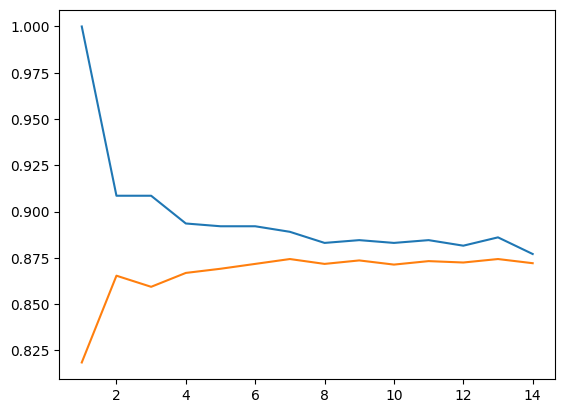

In [15]:
# the bigger the n you use to get the mode:
# -> the better is the training
# -> the worse is the testing
plt.plot(train_knn_values.keys(), train_knn_values.values())
plt.plot(test_knn_values.keys(), test_knn_values.values())

In [16]:
(y_test['churn'] == y_test['prediction']).sum()/y_test.shape[0]

0.0

### Exercise: end of chapter: verifying accuracy (correct / all) depending on how many neighbors

Text(0.5, 1.0, 'this is overfitting: the blue line is bigger than the orange one. Predicting on the training gives better results than on the test')

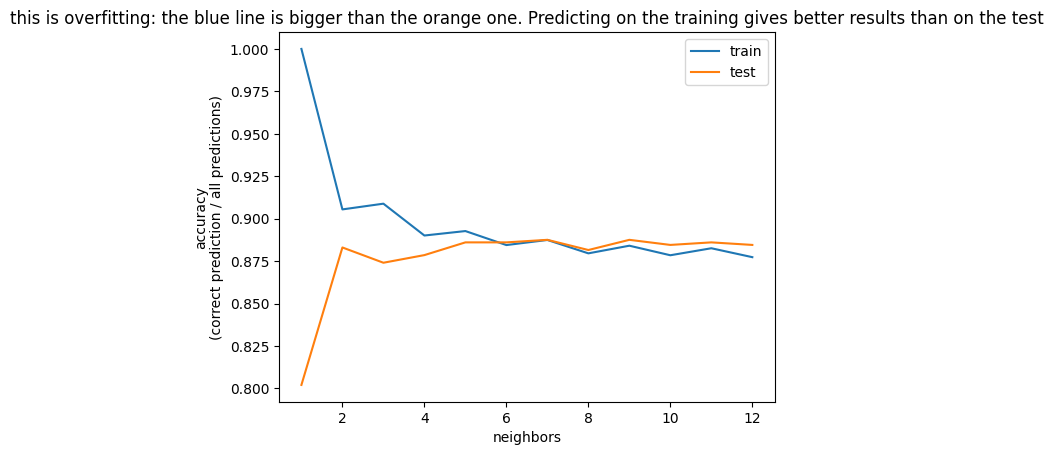

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X = churn_df.drop('churn', axis = 1)
y = churn_df['churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y)

neighbors = np.arange(1,13)
train_accuracies = []
test_accuracies = []

for n in neighbors:
    knn = KNeighborsClassifier(n_neighbors=n)
    knn.fit(X_train, y_train)
    accuracy_train = knn.score(X_train, y_train)
    accuracy_test = knn.score(X_test, y_test)
    train_accuracies.append(accuracy_train)
    test_accuracies.append(accuracy_test)

plt.plot(neighbors, train_accuracies, label = 'train')
plt.plot(neighbors, test_accuracies, label = 'test')
plt.legend()
plt.xlabel('neighbors')
plt.ylabel('accuracy\n(correct prediction / all predictions)')
plt.title('this is overfitting: the blue line is bigger than the orange one. Predicting on the training gives better results than on the test')


# Chapter 2

Regression

```python
X = diabetes_df.drop('glucose', axis = 1).values
y = diabetes_df['glucose'].values

X_bmi = X[:,3]
X_bmi = X_bmi.reshape(-1,1)

from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_bmi, y)
predictions = reg.predict(X_bmi)
```

Dataset: sales_df - advertising campaign


In [18]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

sales_df = pd.read_csv('tables/advertising_and_sales_clean.csv')

X = sales_df['radio'].values
y = sales_df['sales']

X = X.reshape(-1,1)

print(X.shape, y.shape)

(4546, 1) (4546,)


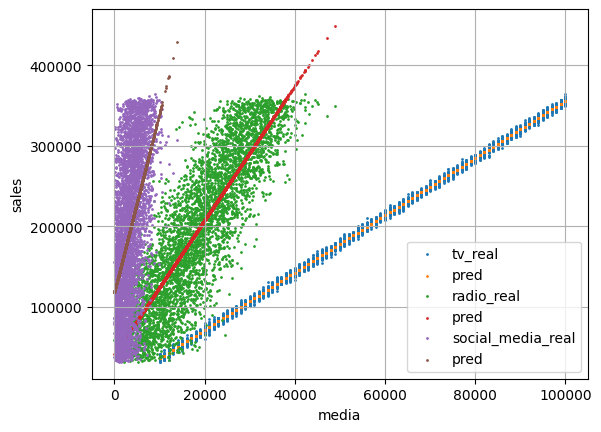

In [20]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()

lr_df = sales_df.copy()

for col in ['tv','radio','social_media']:
    lr_df[col] = reg.fit(sales_df[[col]], sales_df['sales']).predict(sales_df[[col]])
    plt.scatter(sales_df[col], sales_df['sales'], label = f'{col}_real', s = 1)
    plt.scatter(sales_df[col], lr_df[col], label = 'pred', s = 1)
plt.legend()
plt.xlabel('media')
plt.ylabel('sales')
plt.grid()

In [21]:
reg.intercept_, reg.coef_

(118672.57173913231, array([22.18786317]))

Regression:

y = ax + b

y = target
x = single feature
a,b = parameters/coefficients of the model;   
a = slope, b = intercept

How do we choose a and b?
- Define an error function for any given line
- Choose the line that minimizes the error function  
Error function = loss function = cost function

Distance between the 'curve' and the y values = residual

Remember: deviations is from mean; residuals is from regression curve!



RSS = Residual Sum of Squares 
```python
RSS = [(y - ŷ)**2 for y, ŷ in zip(yaxis, prediction)] 
```

Type of linear regression that minimizes RSS: Ordinary Least Squares (OLS)
(MMQ? Método dos mínimos quadrados?)

Higher dimensions:
y = a1x1 + a2x2 + b



-> Multiplar linear regression


```python
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)
# sklearn is doing OLS under the hood
reg_all = LinearRegression()
reg_all.fit(X_train, y_train)
y_pred = reg_all.predict(X_test)
```



R-squared (r2) - quantifies the variance in target values
- values range from 0 to 1  
R2 is the one that is highly influenced by the slope: the lower, lower the R2  
R2 is also the squared value of ... sth (pearson correlation perhaps?)

Calculating Rsquared:
```python
reg_all.score(X_test, y_test)
```



MSE = Mean Squared Error = RMSE/n

```python
from sklearn.metrics import mean_squared_error
mean_squared_error(y_test, y_pred, squared = False)
```

In [22]:
# Create X and y arrays
from sklearn.model_selection import train_test_split

X = sales_df.drop(["sales",'influencer'], axis=1).values
y = sales_df["sales"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Instantiate the model
reg = LinearRegression()

# Fit the model to the data
reg.fit(X_train,y_train)

# Make predictions
y_pred = reg.predict(X_test)
y_pred = [round(x,2) for x in y_pred]
print("Predictions: {}, Actual Values: {}".format(y_pred[:2], y_test[:2]))

Predictions: [53176.66, 70996.2], Actual Values: [55261.28 67574.9 ]


In [23]:
# Import mean_squared_error
from sklearn.metrics import mean_squared_error

# Compute R-squared
r_squared = reg.score(X_test, y_test)

# Compute RMSE
rmse = mean_squared_error(y_test, y_pred, squared=False)

# Print the metrics
print("R^2: {}".format(r_squared))
print("RMSE: {}".format(rmse))

R^2: 0.9990152104759368
RMSE: 2944.433269006057


#### Cross validation
K-fold cross validation:
- split the data into n folds  
- train the data on fold 1 
- test the data on remaining folds  
- collect intercept, coefficients, MSE and R2
- repeat the process for all remaining folds

```python
from sklearn.model_selection import cross_val_score, KFold
kf = KFold(n_splits = 6, shuffle = True, random_state = 42)
reg = LinearRegression()
cv_results = cross_val_score(reg, X, y, cv=kf)
print(cv_results)
```

In [24]:
sales_df

,tv,radio,social_media,influencer,sales
0,"16,000.00","6,566.23","2,907.98",Mega,"54,732.76"
1,"13,000.00","9,237.76","2,409.57",Mega,"46,677.90"
2,"41,000.00","15,886.45","2,913.41",Mega,"150,177.83"
3,"83,000.00","30,020.03","6,922.30",Mega,"298,246.34"
4,"15,000.00","8,437.41","1,406.00",Micro,"56,594.18"
...,...,...,...,...,...
4541,"26,000.00","4,472.36",717.09,Micro,"94,685.87"
4542,"71,000.00","20,610.69","6,545.57",Nano,"249,101.92"
4543,"44,000.00","19,800.07","5,096.19",Micro,"163,631.46"
4544,"71,000.00","17,534.64","1,940.87",Macro,"253,610.41"


In [25]:
# Import the necessary modules
from sklearn.model_selection import cross_val_score, KFold 
from sklearn.linear_model import LinearRegression
import pandas as pd 
import numpy as np

sales_df = pd.read_csv('tables/advertising_and_sales_clean.csv')
X = sales_df.drop(['sales','influencer'], axis = 1)
y = sales_df['sales']

# Create a KFold object
kf = KFold(n_splits = 6, shuffle = True, random_state = 5)

reg = LinearRegression()

# Compute 6-fold cross-validation scores
cv_scores = cross_val_score(reg, X, y, cv = kf )
np.mean(cv_scores)

0.9989896443678249

In [26]:
X

,tv,radio,social_media
0,"16,000.00","6,566.23","2,907.98"
1,"13,000.00","9,237.76","2,409.57"
2,"41,000.00","15,886.45","2,913.41"
3,"83,000.00","30,020.03","6,922.30"
4,"15,000.00","8,437.41","1,406.00"
...,...,...,...
4541,"26,000.00","4,472.36",717.09
4542,"71,000.00","20,610.69","6,545.57"
4543,"44,000.00","19,800.07","5,096.19"
4544,"71,000.00","17,534.64","1,940.87"


In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.5, random_state = 42)
reg.fit(X_train,y_train)
reg.score(X,y)

0.9989932003060956

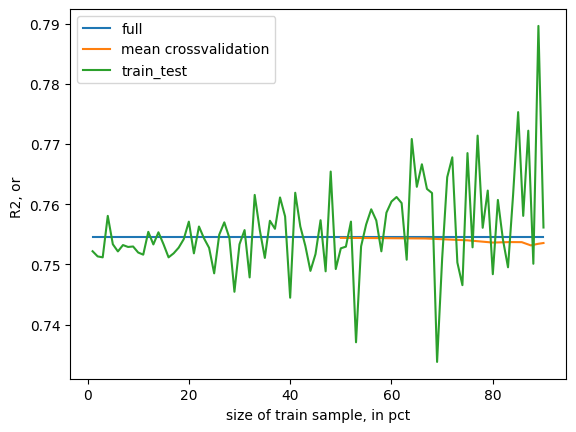

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.metrics import mean_squared_error

X = sales_df.drop(['sales', 'influencer','tv'], axis = 1)
y = sales_df['sales']

reg_full = LinearRegression()
reg_train_full = LinearRegression()
reg_train_test = LinearRegression()
reg_train_train = LinearRegression()
reg_crossval = LinearRegression()

l_r2_full = []
l_r2_train = []
l_r2_test = []
l_r2_train_full = []
l_r2_crossval = []

for x in range(1,91):

    #full
    reg_full.fit(X,y)
    y_pred_full = reg_full.predict(X)
    full_r2, full_rmse = reg_full.score(X,y), mean_squared_error(y, y_pred_full, squared = False)
    l_r2_full.append(full_r2)
    
    # for training:
    X_train, X_test, y_train, y_test = train_test_split(X,y, train_size = x/100)

    # train-full
    reg_train_full.fit(X_train, y_train)
    y_pred_train_full = reg_train_full.predict(X)
    train_full_r2, train_full_rmse = reg_train_full.score(X, y), mean_squared_error(y, y_pred_train_full, squared = False)
    l_r2_train_full.append(train_full_r2)
    
    # train-test
    reg_train_test.fit(X_train, y_train)
    y_pred_train_test = reg_train_test.predict(X_test)
    train_test_r2, train_test_rmse = reg_train_test.score(X_test, y_test), mean_squared_error(y_test, y_pred_train_test, squared = False)
    l_r2_test.append(train_test_r2)

    # train-train
    reg_train_train.fit(X_train, y_train)
    y_pred_train_train = reg_train_train.predict(X_train)
    train_train_r2, train_train_rmse = reg_train_train.score(X_train, y_train), mean_squared_error(y_train, y_pred_train_train, squared = False)
    l_r2_train.append(train_train_r2)
    
for x in range(2,11):
    # cross-validation
    kf = KFold(n_splits = x, shuffle = True)
    cv_scores = cross_val_score(reg_crossval, X, y, cv = kf)    
    mean_cv_score = np.mean(cv_scores)
    l_r2_crossval.append(mean_cv_score)
    
    

plt.plot(range(1,91), l_r2_full, label = 'full')
# plt.plot(range(1,91), l_r2_train_full, label = 'train_full')
# plt.plot(range(1,91), l_r2_train, label = 'train_train')

crosssval_xaxis = [(1 - 1/x)*100 for x in range(2,11)]
plt.plot(crosssval_xaxis, l_r2_crossval, label = 'mean crossvalidation')


plt.plot(range(1,91), l_r2_test, label = 'train_test')
plt.legend()
plt.xlabel('size of train sample, in pct')
plt.ylabel('R2, or ')


plt.show()
# pd.DataFrame(
#     {
#         'order':['full','train-test','train_train','crossval'],
#         'r2 (higher - better)':[full_r2, train_test_r2, train_train_r2, 0],
#         'rmse (lower - better)':[full_rmse, train_test_rmse, train_train_rmse, 0]
#     }
# )


In [29]:
X_train.shape, X_test.shape

((4091, 2), (455, 2))

In [30]:
kf = KFold(n_splits = 4)
kf.get_n_splits(X)
print(kf)

KFold(n_splits=4, random_state=None, shuffle=False)


In [31]:
for train_index, test_index in kf.split(X):
    print('TRAIN:', len(train_index), 'TEST: ' , len(test_index))

TRAIN: 3409 TEST:  1137
TRAIN: 3409 TEST:  1137
TRAIN: 3410 TEST:  1136
TRAIN: 3410 TEST:  1136


#### Regularized regression: ridge & lasso

1- Ridge: OLS loss function + squared sum of each coef * alpha; alpha = hyperparameter
```python
from sklearn.linear_model import Ridge
scores = []
for alpha in [0.1,1,10,100,1000]:
    ridge = Ridge(alpha = alpha)
    ridge.fit(X_train, y_train)
    y_pred = ridge.predict(X_test)
    scores.append(ridge.score(X_test, y_test))    
    
```

2- Lasso: OLS loss function + sum of each absolute value of coef * alpha
```python
from sklearn.linear_model import Lasso
scores = []
for alpha in [0.1,1,10,100,1000]:
    lasso = Lasso(alpha = alpha)
    lasso.fit(X_train, y_train)
    lasso_pred = lasso.predict(X_test)
    scores.append(lasso.score(X_test, y_test))
```

2.1 - Use lasso for feature selection

```python
from sklearn.linear_model import Lasso
X = diabetes_df.drop('glucose', axis = 1)
y = diabetes_df['glucose']
names = X.columns
lasso = Lasso(alpha = 0.1)
lasso_coef = lasso.fit(X,y).coef_
plt.bar(names, lasso_coef)
plt.xticks(rotation = 45)
plt.show()
```

coef
[ 3.56 -0.    0.05] [ 3.56 -0.    0.05] [3.56 0.   0.02]
score
1.0 1.0 1.0


<BarContainer object of 3 artists>

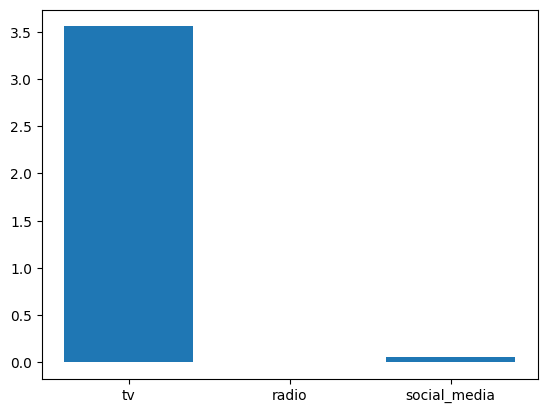

In [32]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split

X = sales_df.drop(['sales', 'influencer'], axis = 1)
y = sales_df['sales']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.5, random_state = 5)

reg = LinearRegression()
ridge = Ridge(alpha = 1)
lasso = Lasso(alpha = 100000)

reg.fit(X_train,y_train)
ridge.fit(X_train,y_train)
lasso.fit(X_train,y_train)

print('coef')
print(np.around(reg.coef_,2), np.around(ridge.coef_,2), np.around(lasso.coef_,2))

print('score')
print(round(reg.score(X,y),2), round(ridge.score(X,y),2), round(lasso.score(X,y),2))

plt.bar(height = reg.coef_, x = X.columns)

# Chapter 3: How good is your model?


Confusion matrix: Fraud detection  
..........................Predicted legit......Predicted Fraudulent  
Actual legitimate...True negative........False Positive  
Actual Fraudulent...False negative.......True Positive  

......PL....PF  
AL...0.....10  
AF...40....50  



- Accuracy:
  - (true positives + true negatives) / all deals
  - in example: number of correclty predicted frauds over all deals
  - high accuracy: most of the deals labeled correctly
      - ex: 0 deals labeled as not fraudulent AND not fraudulent + 50 deals labeled as fraudulent AND fraudulent out of 100 deals total 
      - P(labeled fraudulent & is fraudulent) + P(labeled not fraudulent & not fraudulent) | P(all) = 50/100



- Precision: predicted positives actually positives
  - true positives/(true positives + false positives)
  - groups with limited resources 
  - aka: positive predictive value 
  - labeled as positive AND is positive / labeled as positive
  - P(A&B) | P(B)
  - in example: number of correctly predicted frauds over all fraud predictions
  - high precision: not many legitimate transactions labeled as fraudulent
      - ex: 50 deals labeled as fraudulent AND fraudulent out of 60 deals labeled as fraudulent
      - (P(labeled fraudulent& is fraudulent)|P(labeled fraudulent)) = 50/60     
      - P(A&B)|P(B)
      - 5/6 fraud predictions are correct - good precision! Not calling many true deals as fraudulent
   


- Recall: proportion of actual positives predicted positive
  - true positives / (true positives + false negatives)
  - diseases; pregnancy 
  - aka sensitivity
  - labeled as positive AND is positive / is positive
  - P(A&C) | P(C)
  - high recall: lower false negative rate: predicted most fraudulent transactions correctly 
    - ex: 50 deals labeled as fraudulent AND fraudulent out of 90 deals that are fraudulent = 50/90
    - 5/9 real frauds detected: average recall - missing many frauds, or calling many frauds as legit
    


- F1 score: harmonic mean of precision and recall
  - 2*((precision * recall)/(precision + recall))
  - 2*( ( P(A&B)|P(B) * P(A&C)|P(C) ) /  (P(A&B)|P(B) + P(A&C)|P(C))   )
  - 2*((50/60 * 50/90) / (50/60 + 50/90)) = 0.67
  - F1 score = 0.67 = almost good?
  


Code: classification_report, confusion_matrix  
 ```python
from sklearn.metrics import classification_report, confusion_matrix
knn = KNeighborsClassifier(n_neighbors = 7)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.4, random_state = 42)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
```

In [33]:

cm = """
|            | Pred neg | Pred Pos |
|------------|:------:|-------:|
| Actual neg |  TN={TN}  | FP={FP}   |
| Actual pos |  FN={FN}  | TP={TP}   |
"""

'actual == pred: (T)rue'
'actual != pred: (F)alse'

'(N)egative = Predicted Negative'
'(T)rue = Predicted True'


print('CANCER')
# AFFECTS EVERYBODY
TP = 33
# FN: MINIMIZE FOR BETTER RECALL
FN = 67
## FP: MINIMIZE FOR BETTER PRECISION
FP = 0

## IRRELEVANT
TN = 0
print(cm.format(
    TN = TN,
    FP = FP,
    FN = FN,
    TP = TP,
))

print(f'accuracy: {(TP + TN)/(TP + TN + FP + FN)}')
print(f'precision = {TP/(TP + FP)}')
print(f'recall = {TP/(TP + FN)}')
print(f'f1 score: {((TP/(TP + FP)) * (TP/(TP + FN)))/((TP/(TP + FP)) + (TP/(TP + FN)))}')
print(
" has cancer; diagnosed as not cancer = Death \n",
"high recall: less people with cancer diagnosed healthy - less false negative \n"
'conclusion: recall prevents death; precision prevents suffering'

)
print('\n')
print('CUSTOMER SEARCH FOR LIMITED TEAM')
FN = 5
TP = 5

TN = 85
FP = 5
print(cm.format(
    TN = TN,
    FP = FP,
    FN = FN,
    TP = TP,
))

print(f'accuracy: {(TP + TN)/(TP + TN + FP + FN)}')
print(f'precision = {TP/(TP + FP)}')
print(f'recall = {TP/(TP + FN)}')
print(f'f1 score: {((TP/(TP + FP)) * (TP/(TP + FN)))/((TP/(TP + FP)) + (TP/(TP + FN)))}')

print(
"is not high value; diagnosed as high value = will waste effort in low value client \n",
"high precision: less people with cancer diagnosed healthy - less false negative"
)


CANCER

|            | Pred neg | Pred Pos |
|------------|:------:|-------:|
| Actual neg |  TN=0  | FP=0   |
| Actual pos |  FN=67  | TP=33   |

accuracy: 0.33
precision = 1.0
recall = 0.33
f1 score: 0.24812030075187969
 has cancer; diagnosed as not cancer = Death 
 high recall: less people with cancer diagnosed healthy - less false negative 
conclusion: recall prevents death; precision prevents suffering


CUSTOMER SEARCH FOR LIMITED TEAM

|            | Pred neg | Pred Pos |
|------------|:------:|-------:|
| Actual neg |  TN=85  | FP=5   |
| Actual pos |  FN=5  | TP=5   |

accuracy: 0.9
precision = 0.5
recall = 0.5
f1 score: 0.25
is not high value; diagnosed as high value = will waste effort in low value client 
 high precision: less people with cancer diagnosed healthy - less false negative


In [34]:
# Assessing a diabetes prediction classifier
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

diabetes_df = pd.read_csv('tables/diabetes_clean.csv')
X = diabetes_df.copy().drop('diabetes', axis = 1)
y = diabetes_df.copy()['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.6, random_state = 42)

knn = KNeighborsClassifier(n_neighbors = 6)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

diab_cf = confusion_matrix(y_test, y_pred)
diab_cr = classification_report(y_test, y_pred)

display(diab_cf)
print(diab_cr)


array([[256,  43],
       [102,  60]], dtype=int64)

              precision    recall  f1-score   support

           0       0.72      0.86      0.78       299
           1       0.58      0.37      0.45       162

    accuracy                           0.69       461
   macro avg       0.65      0.61      0.62       461
weighted avg       0.67      0.69      0.66       461



In [35]:
34/(34+46)

0.425

In [36]:
(72+58)/2, (72*58)**(1/2)

(65.0, 64.62197768561404)

In [37]:
import numpy as np
df_cf = (
    pd.DataFrame({'real':y_test, 'pred':y_pred})
    .assign(tf = lambda x: np.where(x['real'] == x['pred'], 'True ', 'False '))
    .assign(posneg = lambda x: np.where(x['pred'] == 1, 'Positive', 'Negative'))
    .assign(cf = lambda x: x['tf'] + x['posneg'])
)

df_cf


,real,pred,tf,posneg,cf
668,0,0,True,Negative,True Negative
324,0,0,True,Negative,True Negative
624,0,0,True,Negative,True Negative
690,0,0,True,Negative,True Negative
473,0,1,False,Positive,False Positive
...,...,...,...,...,...
115,1,0,False,Negative,False Negative
732,1,0,False,Negative,False Negative
467,0,0,True,Negative,True Negative
94,0,0,True,Negative,True Negative


In [38]:
cf = df_cf['cf'].value_counts().sort_index()

print('Support pos: real pos:', y_test.sum())
print('Support neg: real neg:', y_test.count() - y_test.sum())
cf

Support pos: real pos: 162
Support neg: real neg: 299


cf
False Negative    102
False Positive     43
True Negative     256
True Positive      60
Name: count, dtype: int64

In [39]:
cf/cf.sum()

cf
False Negative   0.22
False Positive   0.09
True Negative    0.56
True Positive    0.13
Name: count, dtype: float64

In [40]:
accuracy = (cf['True Positive'] + cf['True Negative'])/df_cf.shape[0]
accuracy


0.6854663774403471

In [41]:
precision_pos = cf['True Positive']/(cf['True Positive']+cf['False Positive'])
precision_neg = cf['True Negative']/(cf['True Negative']+cf['False Negative'])
precision_pos, precision_neg

(0.5825242718446602, 0.7150837988826816)

In [42]:
recall_pos = cf['True Positive']/(cf['True Positive']+cf['False Negative'])
recall_neg = cf['True Negative']/(cf['True Negative']+cf['False Positive'])
recall_pos, recall_neg

(0.37037037037037035, 0.8561872909698997)

In [43]:
fscore_pos = (2/((1/recall_pos) + (1/precision_pos)))
fscore_neg = (2/((1/recall_neg) + (1/precision_neg)))
fscore_pos, fscore_neg

(0.45283018867924524, 0.7792998477929984)

In [44]:
classification_report?

Signature:
classification_report(
    y_true,
    y_pred,
    *,
    labels=None,
    target_names=None,
    sample_weight=None,
    digits=2,
    output_dict=False,
    zero_division='warn',
)
Docstring:
Build a text report showing the main classification metrics.

Read more in the :ref:`User Guide <classification_report>`.

Parameters
----------
y_true : 1d array-like, or label indicator array / sparse matrix
    Ground truth (correct) target values.

y_pred : 1d array-like, or label indicator array / sparse matrix
    Estimated targets as returned by a classifier.

labels : array-like of shape (n_labels,), default=None
    Optional list of label indices to include in the report.

target_names : list of str of shape (n_labels,), default=None
    Optional display names matching the labels (same order).

sample_weight : array-like of shape (n_samples,), default=None
    Sample weights.

digits : int, default=2
    Number of digits for formatting output floating point values.
    When `

Logistic regression and the ROC curve

logistic regression: calculates prob that p is from a specific class.  
- if p>0.5: 1; else: 0
- default treshold = 0.5
- 

```python
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
X_train, X_test, y_train, y_test = train_test_split(X,y)
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)
y_pred_probs = logreg.predict_proba(X_test)[:,1] # probability for the positive probability
```



ROC curve  
Receiver Operating Characteristic curve  
Chart: y = true positive rate; x = false positive rate
- if y = 0: p=1 for all
```python
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)
plt.plot([0,1],[0,1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('Logistic Regression ROC Curve')
plt.show()
```


ROC AUC  
Area under the ROC curve 
```python
from sklearn.metrics import roc_auc_score
print(roc_auc_score(y_test, y_pred_probs))
```

In [45]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

diabetes_df = pd.read_csv('tables/diabetes_clean.csv')

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = diabetes_df.copy().drop('diabetes', axis = 1)
y = diabetes_df.copy()['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.6, random_state = 42)

logreg = LogisticRegression()
logreg.fit(X_train, y_train)

y_pred_probs = logreg.predict_proba(X_test)[:,1] # only the odds of being positive


f:\git\env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [46]:
import numpy as np 
from sklearn.metrics import roc_curve, precision_score, confusion_matrix
import matplotlib.pyplot as plt 

#y = y_true = true values
y = np.array([1,1,2,2])

# scores = y_score = target scores. Probability estimate of positive
scores = np.array([0.1, 0.4, 0.35, 0.8])

# interpretation
text = 'The probability of {y_val} being considered positive is of {score_val}%'
texts = [text.format(y_val = y_val, score_val = score_val) for y_val, score_val in zip (y,scores)]
# print('\n'.join(texts))


#threshold

text = '''Threshold {th}: 
True = {tr}; 
Score = {sc};
Predicted:  {pr};''' 
for th in [0, 0.3, 0.38, 0.6, 1]:
    preds = np.where(scores > th,2,1)
    print(text.format(th = th, tr = y, pr = preds, sc = scores))
    print(confusion_matrix(y, preds))
    print('TPR = ', precision_score(y, preds, pos_label = 2))
    print('\n')

fpr, tpr, thresholds = roc_curve(y, scores, pos_label = 1)
[(
    # f'{y_val = }', 
    # f'{score_val = }', 
    f'fpr:{x}', 
    f'tpr: {y}', 
    f'threshold {z}'
    ) for y_val, score_val, x,y,z in zip(y, scores, fpr,tpr, thresholds)]



Threshold 0: 
True = [1 1 2 2]; 
Score = [0.1  0.4  0.35 0.8 ];
Predicted:  [2 2 2 2];
[[0 2]
 [0 2]]
TPR =  0.5


Threshold 0.3: 
True = [1 1 2 2]; 
Score = [0.1  0.4  0.35 0.8 ];
Predicted:  [1 2 2 2];
[[1 1]
 [0 2]]
TPR =  0.6666666666666666


Threshold 0.38: 
True = [1 1 2 2]; 
Score = [0.1  0.4  0.35 0.8 ];
Predicted:  [1 2 1 2];
[[1 1]
 [1 1]]
TPR =  0.5


Threshold 0.6: 
True = [1 1 2 2]; 
Score = [0.1  0.4  0.35 0.8 ];
Predicted:  [1 1 1 2];
[[2 0]
 [1 1]]
TPR =  1.0


Threshold 1: 
True = [1 1 2 2]; 
Score = [0.1  0.4  0.35 0.8 ];
Predicted:  [1 1 1 1];
[[2 0]
 [2 0]]
TPR =  0.0




f:\git\env\Lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


[('fpr:0.0', 'tpr: 0.0', 'threshold 1.8'),
 ('fpr:0.5', 'tpr: 0.0', 'threshold 0.8'),
 ('fpr:0.5', 'tpr: 0.5', 'threshold 0.4'),
 ('fpr:1.0', 'tpr: 0.5', 'threshold 0.35')]

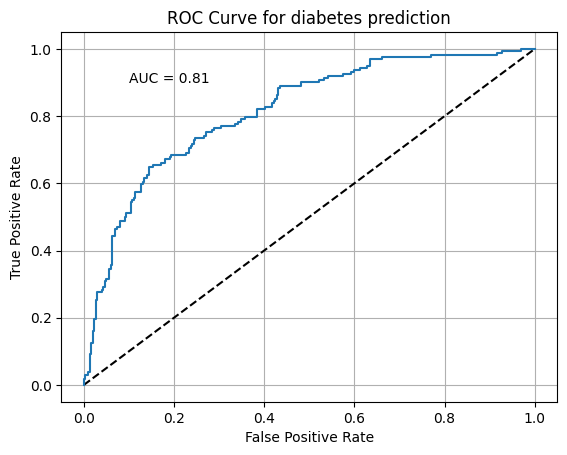

In [47]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, tresholds = roc_curve(y_test, y_pred_probs)
score = roc_auc_score(y_test, y_pred_probs)
score = round(score,2)
plt.text(0.1,0.9, f'AUC = {score}')
plt.plot([0,1], [0,1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for diabetes prediction')
plt.grid()


Hyperparameter tuning
- parameters specified before fitting the model
- Examples:
 - Ridge/ Lasso regression: alpha
 - KNN: n_neighbors (ex: 2,3,4), metric (ex: euclidean, manhattan)
- cross validation: essential

code: GridSearchCV
```python
from sklearn.model_selection import GridSearchCV
kf = KFold(n_splits = 5, shuffle = True, random_state = 42)
param_grid = {
    'alpha': np.arange(1e-4, 1, 10),
    'solver': ['sag','lsqr'],
}
ridge = Ridge()

ridge_cv = GridSearchCV(
    ridge, # row 10
    param_grid, # row 5
    cv = kf, # row 4
    )
ridge_cv.fit(X_train, y_train)

print(ridge_cv.best_params_, ridge_cv.best_score_)
```

Code: RandomizedSearchCV
```python
from sklearn.model_selection import RandomizedSearchCV
kf = KFold(n_splits = 5, shuffle = True, random_start = 42)
param_grid = {
    'alpha': np.arange(1e-4,1,10),
    'solver': ['sag','lsqr'],
}
ridge = Ridge()
ridge_cv = RandomizedSearchCV(
    ridge, 
    param_grid, 
    cv = kf, 
    n_iter = 2 # new row
    )
ridge_cv.fit(X_train, y_train)
print(ridge_cv.best_params_, ridge_cv.best_score_)

Time to practice!

In [49]:
import pandas as pd 
from sklearn.model_selection import KFold
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
import numpy as np

diabetes_df = pd.read_csv('tables/diabetes_clean.csv')
X = diabetes_df.copy().drop('diabetes', axis = 1)
y = diabetes_df.copy()['diabetes'] 

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.3,
    random_state= 42,
)
kf = KFold(n_splits = 5, shuffle = True, random_state = 42)
param_grid = {
    'alpha': np.linspace(1e-5, 1, 20),    
}

lasso = Lasso()

lasso_cv = GridSearchCV(
    estimator = lasso,
    param_grid = param_grid,
    cv = kf
)

lasso_cv.fit(X_train, y_train)
print(f'Tuned lasso parameters: {lasso_cv.best_params_}')
print(f'Tuned lasso score (R squared): {lasso_cv.best_score_}')

Tuned lasso parameters: {'alpha': 1e-05}
Tuned lasso score (R squared): 0.29604708033272703


In [50]:
diabetes_df.head(2)

,pregnancies,glucose,diastolic,triceps,insulin,bmi,dpf,age,diabetes
0,6,148,72,35,0,33.60,0.63,50,1
1,1,85,66,29,0,26.60,0.35,31,0


In [51]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression 

# Create the parameter space
params = {
    # 'penalty': [ 'l1','l2'],
    'tol': np.linspace(1e-5,1,5),
    # 'C': np.linspace(0.1, 1, 5),
    # 'class_weight': ['balanced',{0:0.8,1:0.2}],
    # 'max_iter' : np.arange(500,1000,10)
}

logreg = LogisticRegression()

# Instantiate the RandomizedSearchCV object
logreg_cv = RandomizedSearchCV(
    logreg, 
    params, 
    cv = kf
    )

# Fit the data to the model
logreg_cv.fit(X, y)

# Print the tuned parameters and score
print(f'Tuned logistic regression parameters: {logreg_cv.best_params_}')
print(f'Tuned logistic regression best accuracy score: {logreg_cv.best_score_}')

f:\git\env\Lib\site-packages\sklearn\model_selection\_search.py:305: UserWarning: The total space of parameters 5 is smaller than n_iter=10. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
f:\git\env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
f:\git\env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/s

Tuned logistic regression parameters: {'tol': 1e-05}
Tuned logistic regression best accuracy score: 0.7695526695526695


f:\git\env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
f:\git\env\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [52]:
logreg_cv.best_score_

0.7695526695526695

# Chapter 4: Preprocessing data

Dealing with categorical features: dummies
- if each variable has only one category, and cannot have no categories, delete one of the categories
- pd.get_dummies()
- sklearn.one_hot_encoder()

pandas get_dummies():
```python
import pandas as pd 
music_df = pd.read_csv('music.csv')
music_dummies = pd.get_dummies(music_df['genre'], drop_first = True)
print(music_dummies.head())

music_dummies = pd.concat([music_df, music_dummies], axis = 1)
music_dummies = music_dummies.drop('genre', axis = 1)

from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression

X = music_dummies.drop('popularity', axis = 1).values
y = music_dummies['popularity'].values

X_train, X_test, y_train, y_test =train_test_split(X,y, test_size = 0.2, random_state = 42)
kf = KFold(n_splits = 5, shuffle = True, random_state = 42)
linreg = LinearRegression()
linreg_cv = cross_val_score(linreg, X_train, y_train, cv = kf, scoring = 'neg_mean_squared_error')
print(np.sqrt(-linreg_cv))

Time to practice!

In [53]:
import pandas as pd 
music_df = pd.read_csv('tables/music_clean.csv')
import numpy as np 
a = ['Rock', 'Blues', 'Jazz', 'Rap', 'Hip-Hop', 'Country',
       'Alternative', 'Electronic', 'Classical', 'Anime']
pt = np.array([500,  61,  60,  60,  59,  57,  56,  53,  48,  46])
pr = pt/sum(pt)

np.random.seed(42)
l = np.random.choice(a = a, p = pr, size = len(music_df))
music_df['genre'] = l
music_df = music_df.filter(regex = '^(?!Unnamed: 0).*$')
music_df.to_csv('tables/music_clean.csv', index = False)
display(music_df.head(2))

music_dummies = pd.get_dummies(music_df, drop_first = True)
display(music_df.head(2).shape)

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,genre
0,60.00,0.90,0.73,"214,547.00",0.18,0.00,0.12,-14.82,0.04,92.93,0.62,Rock
1,63.00,0.00,0.64,"190,448.00",0.91,0.08,0.24,-4.79,0.06,110.01,0.64,Classical


(2, 12)

In [54]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
# Create X and y
X = music_dummies.drop('popularity', axis = 1)
y = music_dummies['popularity']

# Instantiate a ridge model
ridge = Ridge(alpha = 0.2)

# Perform a cross-validation
scores = cross_val_score(ridge, X, y, cv = kf, scoring = 'neg_mean_squared_error')

# Calcualte RMSE
rmse = np.sqrt(-scores)
print(f'average RMSE: {np.mean(rmse)}')
print(f'Standard deviation of the target array: {np.std(y)}')

average RMSE: 12.61080158244709
Standard deviation of the target array: 14.02156909907019


Handling missing data

- drop na
- if fillna, split data first before imputing to avoid data leakage

Objective: input data into train and test pipeline avoiding data leakage
```python
from sklearn.impute import SimpleImputer
X_cat = music_df['genre'].values.reshape(-1,1)
X_num = music_df.drop(['genre','popularity'], axis = 1).values
y = music_df['popularity'].values

X_train_cat, X_test_cat, y_train, y_test = train_test_split(X_cat, y, test_size = 0.2, random_state = 12)
X_traim_num, X_test_num, y_train, y_test = train_test_split(X_nu,m y, test_size = 0.2, random_state = 12)

imp_cat = SimpleImputer(strategy = 'most_frequent')
X_train_cat = imp_cat.fit_transform(X_train_cat)
X_test_cat = imp_cat.fit_transform(X_test_cat)

imp_num = SimpleImputer(strategy = 'most_frequent')
X_train_num = imp_num.fit_transform(X_train_num)
X_test_num = imp_num.fit_transform(X_test_num)

X_train = np.append(X_train_num, X_train_cat, axis = 1)
X_test = np.append(X_test_num, X_train_cat, axis = 1)
```

pipeline: input data

Objective: drop rows where column has few missing; predict rock

```python
from sklearn.pipeline import Pipeline
music_df = music_df.dropna(
    subset = ['genre','popularity','loudness','liveness','tempo']
)
music_df['genre'] = np.where(music_df['genre'] == 'Rock',1,0)
X = music_df.drop('genre', axis = 1).values
y = music_df['genre'].values

steps = [
    ('imputation', SimpleImputer()),
    ('logistic_regression', LogisticRegression())
]

pipeline = Pipeline(steps)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

pipeline.fit(X_train, y_train)
pipeline.score(X_test, y_test)

Time to practice!

In [55]:
# import libraries and dataset
import pandas as pd 
import numpy as np 
music_df = pd.read_csv('tables/music_clean.csv')

# Remove values where less than 5% are missing
# would make sense if dataset were correct
music_df = music_df.dropna(subset = ["genre", "popularity", "loudness", "liveness", "tempo"])

# Convert genre to a binary feature
music_df['genre'] = np.where(music_df['genre'] == "Rock", 1,0)


In [56]:
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer 
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier


# Instantiate an imputer 
imputer = SimpleImputer()


# Instantiate a knn model
knn = KNeighborsClassifier(n_neighbors = 3)

# Build steps for the pipeline
steps = [
    ('imputer', imputer),
    ('knn', knn)
]

# split the data
X = music_df.drop('genre', axis = 1)
y = music_df['genre']
X_train, X_test, y_train, y_test = train_test_split(X, y)

# create the pipeline
pipeline = Pipeline(steps = steps)

# Fit the pipeline to the training data
pipeline.fit(X_train, y_train)

# make predictions on the test set
y_pred = pipeline.predict(X_test)


# Print the confusion matrix
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[69 60]
 [45 76]]
              precision    recall  f1-score   support

           0       0.61      0.53      0.57       129
           1       0.56      0.63      0.59       121

    accuracy                           0.58       250
   macro avg       0.58      0.58      0.58       250
weighted avg       0.58      0.58      0.58       250



In [57]:
66/(66+67); 66/(66+50)

0.5689655172413793

Centering and scaling (StandardScaler)

- normalize or standardize the data
- subtract mean and divide by variance

```python
from sklearn.preprocessing import StandardScaler
X = music_df.drop('genre', axis = 1)
y = music_df['genre']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state = 42)

scaler = StandardScaler
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(np.mean(X), np.std(X))
print(np.mean(X_train_scaled), np.std(X_train_scaled))

Scaling in a pipeline
```python
steps = [
    ('scaler', StandardScaler()),
    ('knn',KNeighborsClassifier(n_neighbors = 6))
]
pipeline = Pipeline(steps)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 21)

knn_scaled =pipeline.fit(X_train, y_train)
y_pred = kn_scaled.predict(X_test)
print(knn_scaled.score(X_test, y_test))

CV and scaling in a pipeline
```python
from sklearn.model_selection import GridSearchCV
steps = [
    ('scaler', StandardScaler()),
    ('knn', KneighborsClassifier())
]
pipeline = Pipeline(steps)
parameters = {'knn__n_neighbors': np.arange(1,50)}
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 21)

cv = GridSearchCV(pipeline, param_grid = parameters)
cv.fit(X_train, y_train)
y_pred = cv.predict(X_test)

print(cv.best_score_, cv.best_params_)

Time to practice!

In [58]:
import pandas as pd 
import numpy as np
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline 

# import data 
music_df = pd.read_csv('tables/music_clean.csv')
music_df['genre'] = np.where(music_df['genre'] == "Rock", 1, 0)
X = music_df.drop('loudness', axis = 1)
y = music_df['loudness']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

# Create pipeline steps
steps = [
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha = 0.5))
    ]

# Instantiate the pipeline
pipeline = Pipeline(steps)
pipeline.fit(X_train, y_train)

# calculate and print R-squared
pipeline.score(X_test, y_test)


0.7185052288252617

In [59]:
# build the steps
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# import data 
music_df = pd.read_csv('tables/music_clean.csv')
music_df['genre'] = np.where(music_df['genre'] == "Rock", 1, 0)
X = music_df.drop('genre', axis = 1)
y = music_df['genre']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)


steps = [
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression()),
]
pipeline = Pipeline(steps)

# create the parameter space
parameters = {
    'logreg__C': np.linspace(0.001, 1, 20)
    }

# Instantiate the grid search object
cv = GridSearchCV(
    pipeline,
    param_grid = parameters
)

#fit to the training data
cv.fit(X_train, y_train)
cv.best_score_, cv.best_params_

(0.5, {'logreg__C': 0.26389473684210524})

In [60]:
y

0      1
1      0
2      0
3      0
4      1
      ..
995    1
996    0
997    1
998    0
999    1
Name: genre, Length: 1000, dtype: int32

Different models for different problems
- size of dataset
- interpretability
- flexibility  

Regression metrics:  
- RMSE, Rsquared  

Classification model performance:
- accuracy
- confusion matrix
- precision, recall, F1-score
- ROC AUC

Train several models and evaluate performance  
   


Models affected by scaling:
- KNN
- Linear regression (plus Ridge, lasso)
- Logistic regression
- Artificial Neural Network

Best to scale our data before evaluating models

Evaluating classification models
```python
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

X = music_df.drop('genre', axis = 1)
y = music['genre']

X_train, X_test, y_train, y_test = train_test_split(X, y , random_state = 42)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Logistic Regression': LogisticRegression(),
    'KNN': KneighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
}
results = []

for model in models.values():
    kf = KFold(n_splits = 6, random_state = 42, shuffle = True)
    cv_results = cross_val_score(model, X_train_scaled, y_train, cv = kf)
    results.append(cv_results)
plt.boxplot(results, labels = models.keys())
plt.show()

Test set performance
```python
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    test_score = model.score(X_test_scaled, y_test)
    print(f'{name} Test Set Accuracy: {test_score}')

Time to practice!

Text(0.5, 1.0, 'comparison of models: Linear regresion and Ridge are the best')

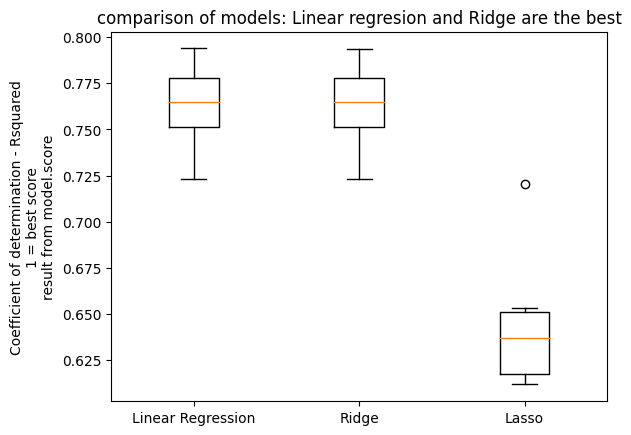

In [61]:
import pandas as pd 
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
import matplotlib.pyplot as plt

music_df = pd.read_csv('tables/music_clean.csv')
music_df = pd.get_dummies(music_df, drop_first= True)

X = music_df.drop('energy', axis = 1)
y = music_df['energy']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha = 0.1),
    'Lasso': Lasso(alpha = 0.1)
}
results = []

kf = KFold(n_splits = 6, random_state= 42, shuffle = True)
# Loop through the model's values 
for model in models.values():
    # perform cross-validation
    cv_scores = cross_val_score(model, X_train, y_train, cv = kf)
    
    # append the results
    results.append(cv_scores)

# create a box plot of the results 
plt.boxplot(results, labels = models.keys())
plt.ylabel('Coefficient of determination - Rsquared\n1 = best score\nresult from model.score')
plt.title('comparison of models: Linear regresion and Ridge are the best')

In [62]:
# Predicting on the test set
# import mean squared error
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

for name, model in models.items():
    # fit the model
    model.fit(X_train_scaled, y_train)
    # make predictions
    y_pred = model.predict(X_test_scaled)
    # calculate RMSE
    test_rmse = mean_squared_error(y_test, y_pred, squared = False)
    print(f'{name} Test set for RMSE: {test_rmse}')
print('Best value: 0')


Linear Regression Test set for RMSE: 0.11071159796996856
Ridge Test set for RMSE: 0.1107141507138864
Lasso Test set for RMSE: 0.17287779153344687
Best value: 0


Text(0.5, 1.0, 'logistic regressions seems to have the best accuracy and lowest discrepancy')

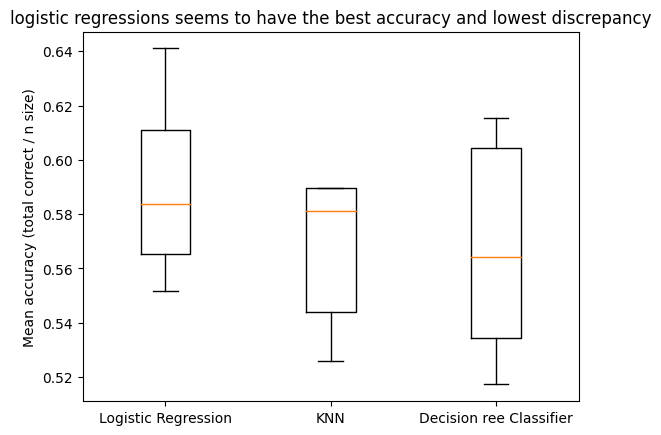

In [63]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

music_df = pd.read_csv('tables/music_clean.csv')
music_df = pd.get_dummies(music_df, drop_first= True)
music_df['popularity'] = np.where(music_df['popularity'] > music_df['popularity'].median(), 1,0)
X = music_df.drop('popularity', axis = 1)
y = music_df['popularity']

X_train, X_test, y_train, y_test =train_test_split(X, y, test_size= 0.3, random_state= 12)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    'Logistic Regression': LogisticRegression(),
    'KNN': KNeighborsClassifier(),
    'Decision ree Classifier': DecisionTreeClassifier()
}
results = []
for model in models.values():
    kf = KFold(n_splits = 6, random_state = 12, shuffle=True)
    # perform cross_validation
    cv_results = cross_val_score(model, X_train_scaled, y_train, cv = kf)
    results.append(cv_results)

plt.boxplot(results, labels = models.keys())
plt.ylabel('Mean accuracy (total correct / n size)')
plt.title('logistic regressions seems to have the best accuracy and lowest discrepancy')

In [64]:
# Pipeline for predicting song popularity
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV

steps = [
    ('imp_mean', SimpleImputer()),
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression()),
]

# set up pipeline
pipeline = Pipeline(steps)
params = {
    'logreg__solver': ['newton-cg', 'saga',' lbfgs'],
    'logreg__C': np.linspace(0.001,1,10)
}

# Create the GridSearchCV object
tuning = GridSearchCV(pipeline, param_grid = params)
tuning.fit(X_train, y_train)
y_pred = tuning.predict(X_test)



f:\git\env\Lib\site-packages\sklearn\model_selection\_validation.py:378: FitFailedWarning: 
50 fits failed out of a total of 150.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "f:\git\env\Lib\site-packages\sklearn\model_selection\_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "f:\git\env\Lib\site-packages\sklearn\pipeline.py", line 405, in fit
    self._final_estimator.fit(Xt, y, **fit_params_last_step)
  File "f:\git\env\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1160, in fit
    self._validate_params()
  File "f:\git\env\Lib\site-packages\sklearn\base.py", line 600, in _validate_par

In [65]:
# Compute and print performance
print(
    f'Tuned Logistic Regression Parameters: {tuning.best_params_}, ',
    f'Accuracy: {tuning.score(X_test, y_test)}'
)

Tuned Logistic Regression Parameters: {'logreg__C': 0.334, 'logreg__solver': 'newton-cg'},  Accuracy: 0.59


# The end!

What I learned:
- supervised learning techniques to build predictive models
- for both regression and classification problems 
- underfitting and overfitting (KNN example with != neighbors)
- how to split data (train_test_split, KFold)
- cross-validation (cross_val_score)
- Data preprocessing techniques (StandardScaler)
- model selection (for loop?)
- Hyperparameter tuning (gridcv)
- Model performance evaluation (model().fit().score(); cross_val_score)
- pipelines

Where to go from here?
- Tree-based models
- Preprocessing for ML
- Model validation
- Feature engineering
- Unsupervised Learning
- Projects

# A little more: PCA
(from unspervised learning in python)


First step: "Decorrelation"
- aligns data with axes
- rotates data samples to be aligned with axes  
- Pricipal components = directions of variance   
- PCA aligns principal components with axes  
```python
from sklearn.decomposition import PCA
model = PCA()
model.fit(samples)
transformed = model.transform(samples)
print(model.components_)
```

results: same table shape
- columns = PCA features  
- values are de-correlated (pearson would be zero)  

     0    1
0 1.00 0.86
1 0.86 1.00
0.8604149377143466 8.121332906194173e-63


(2.55985, 4.10315, -0.33375000000000093, 7.00875)

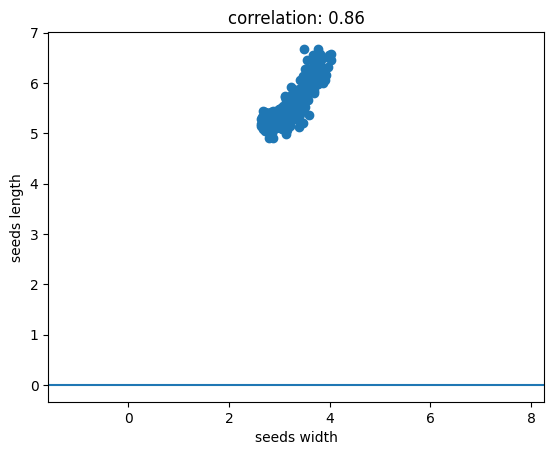

In [66]:
import matplotlib.pyplot as plt 
import pandas as pd 
from scipy.stats import pearsonr

grains = pd.read_csv('tables/seeds-width-vs-length.csv', header = None)
grains

plt.scatter(grains[0], grains[1])
print(grains.corr())

correlation, pvalue = pearsonr(grains[0], grains[1])
print(correlation, pvalue)

plt.title(f'correlation: {round(correlation, 2)}')
plt.xlabel('seeds width')
plt.ylabel('seeds length')
plt.axhline(y = 0)
plt.axis('equal')


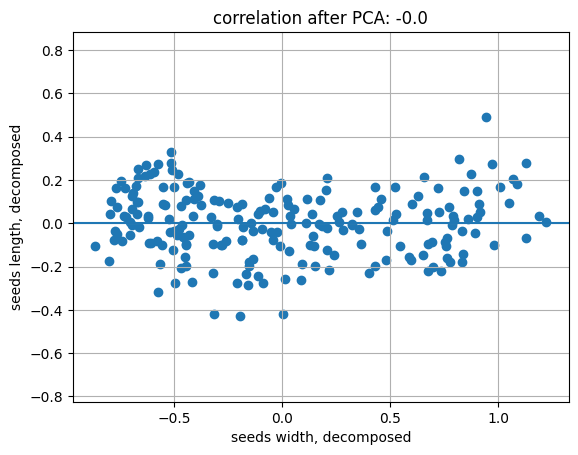

In [67]:
from sklearn.decomposition import PCA

model = PCA()

pca_features = model.fit_transform(grains)

plt.scatter(pca_features[:,0], pca_features[:,1])
plt.axis('equal')

correlation, pvalue = pearsonr(pca_features[:,0], pca_features[:,1])
correlation

plt.title(f'correlation after PCA: {round(correlation, 2)}')
plt.xlabel('seeds width, decomposed')
plt.ylabel('seeds length, decomposed')
plt.axhline(y = 0)

plt.grid()

Intrinsinc dimension
- number of variables needed in a minimal representation of the data  
- number of features needed to apprximate the dataset 
- features = dimension = columns of dataset  
- if 3 features (x, y, z), but all data points lie on a plane (z the same for all): 2 intrinsinc dimensions 
- chart: y - variance; x = PCA feature (?)

Bing:
The difference between PCA variance and regular variance is that PCA variance is the proportion of the total variance explained by each principal component. It is calculated by dividing the eigenvalue of each principal component by the sum of all eigenvalues. Regular variance, on the other hand, is simply the average squared deviation from the mean.

```python
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(samples)
features = range(pca.n_components_)
plt.bar(features, pca.explained_variance_)
plt.xticks(features)
plt.ylabel('variance')
plt.xlabel('PCA feature')
plt.show()


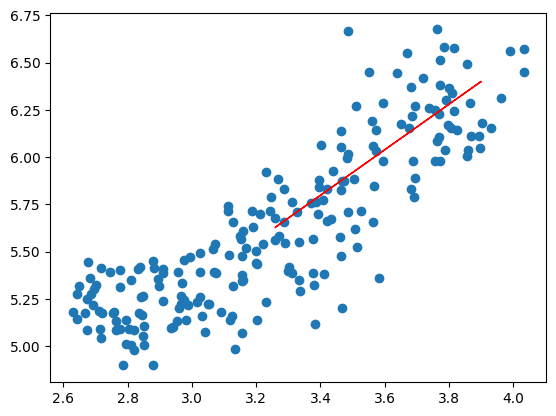

In [68]:
import matplotlib.pyplot as plt 
from sklearn.decomposition import PCA 

# Make a scatter plot of the untransformed points
plt.scatter(grains[0], grains[1])

# Create a PCA instance: model
model = PCA() 


# Fit model to points
model.fit(grains)

# get the mean of the grain samples: mean
mean = model.mean_

# Get the first principal component:first_pc
first_pc = model.components_[0,:]

# Plot first_pc as an arrow, starting at mean

plt.arrow(mean[0], mean[1], first_pc[0], first_pc[1], color = 'red')

Text(0.5, 1.0, 'Scree plot: \nGraphical representation of the eigenvalues \nof factors of PCA High variance: Informative; low variance: noisy')

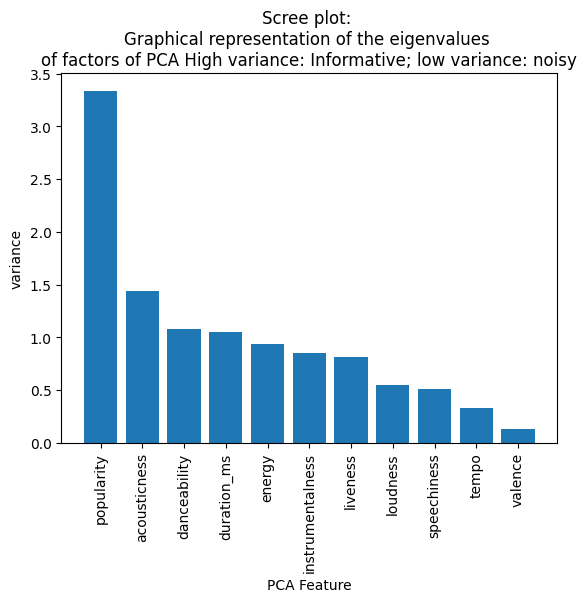

In [69]:
from sklearn.pipeline import make_pipeline 
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt

music_df = pd.read_csv('tables/music_clean.csv')
music_df = music_df.select_dtypes('number')

# Create a PCA instance: pca
pca = PCA()

# Create scaler
scaler = StandardScaler()

# create pipeline
pipeline = make_pipeline(scaler, pca)

# Fit the pipeline to dataset
pipeline.fit(music_df)

# Plot the explained variances
features = music_df.columns 

plt.bar(features, pca.explained_variance_)
plt.xticks(features, rotation = 90)
plt.xlabel("PCA Feature")
plt.ylabel('variance')
plt.title('''Scree plot: 
Graphical representation of the eigenvalues 
of factors of PCA High variance: Informative; low variance: noisy''')

In [70]:
import numpy as np
np.cumsum(pca.explained_variance_)

array([ 3.33744727,  4.77465794,  5.8537719 ,  6.89973004,  7.83685123,
        8.69118665,  9.50069722, 10.04772431, 10.55284258, 10.88442398,
       11.01101101])

Dimension reduction
- represents same data, using less features
- can be performed using PCA  
- keeps high variance (eigenvalue variance)

```python
from sklearn.decomposition import PCA
pca = PCA(n_comonents = 2)
pca.fit(samples)
transformed = pca.transform(samples)
print(transformed.samples)
```

Sparse arrays and csr_matrix
- scipy.sparce.csr_matrix instead of Numpy array
- csr_matrix remembers only the non-zero entries (save space!)
- csr_matrix = sklearn TruncatedSVD
```python
from sklearn.decomposition import TruncatedSVD
model = TruncatedSVD(n_components = 3)
model.fit(documents) # documents is csr_matrix
transformed = model.transform(documents)